In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

C:\Users\baraj\Documents\Code\NMaCh-TP\Code\Notebooks\..\util\overshoots.py:224: SyntaxWarning: invalid escape sequence '\s'
  """


# Loading in data

## Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

https://zenodo.org/records/11108741 for actual data set

In [3]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

## GTPR2025 Tipping elements

In [2]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

# Simulations

In [4]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [5]:
baseline = 'CurPol_OS_1.5C'
temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

print(popt)

[  1.10009253   3.30206669   1.50422    103.28176735   3.4404387
 163.72772026]


In [6]:
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

years = np.arange(2015,2301)
no_years=len(years)

In [7]:
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in tqdm.tqdm(range(1,no_burn_years)):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

100%|█████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 17548.94it/s]


In [18]:
T_peaks.shape

(51,)

In [19]:
# pcs = np.ones((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
# prs = np.ones((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
D = np.zeros((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
d_samps = np.zeros((len_sample,no_years,len(df_TEs)))
d_samps[:,0,:] = D_burn
# D[:,:,]
temps = np.ones((len(T_peaks), len(T_oss), no_years))
PAR = np.copy(popt)
for i in tqdm.tqdm(range(T_peaks.shape[0])):
    for j in range(i): # T_os can only be less than T_peak
        PAR[1:3] = [T_peaks[i], T_oss[j]]
        temps[i,j,:] = OS_model(xdata,*PAR)
        D[i,j,0,:] = D_burn.mean(axis=0)
        for t in range(1,no_years):
            pc = q_c*temp_response(temps[i,j,t], T_lim, betas)
            pr = q_r*(1- temp_response(temps[i,j,t], T_lim, betas))
            for r in range(len_sample):
                d_samps[r,t,:] = environmental_update(d_samps[r,t-1,:], A[r],pc=pc,pr=pr)
        D[i,j,:,:] = d_samps.mean(axis=0)
                # D[i,j,t,:] = environmental_update(D[i,j,r,t-1,:], 
                #                                     A[r], 
                #                                     pc = pcs[i,j,t,:],
                #                                     pr = prs[i,j,t,:])

100%|██████████████████████████████████████████████████████████████████████████████████| 51/51 [43:53<00:00, 51.64s/it]


In [35]:
D_nr = np.delete(D,6,axis=-1)
AR_popt = np.array([k_risk(D_nr[:,:,-1,:],k,axis=2) 
                     for k in range(1,D_nr.shape[-1]+1)]) 
# R_data = np.array([np.max(pars[i].reshape(1,
#                                           len(pars[i]),1)*(AR_popt[i]<=0.1), 
#                           axis=1) 
#                    for i in range(6)]) # R_data to differentiate with r_data

Text(0, 0.5, 'T_os')

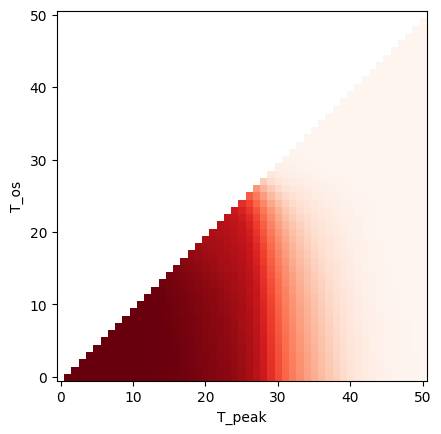

In [62]:
# Lower triangle mask
lower_mask = np.tri(AR_popt.shape[1], AR_popt.shape[2], k=0)

# Upper triangle mask
upper_mask = lower_mask.T
plt.imshow(np.ma.array(AR_popt[0,:,:].transpose(),mask=lower_mask),cmap='Reds_r',
           # extent=(T_peaks[0], T_peaks[-1], T_oss[0], T_oss[-1]),
           origin='lower')
plt.xlabel('T_peak')
plt.ylabel('T_os')

In [52]:
help(np.tri)

Help on function tri in module numpy:

tri(N, M=None, k=0, dtype=<class 'float'>, *, like=None)
    An array with ones at and below the given diagonal and zeros elsewhere.

    Parameters
    ----------
    N : int
        Number of rows in the array.
    M : int, optional
        Number of columns in the array.
        By default, `M` is taken equal to `N`.
    k : int, optional
        The sub-diagonal at and below which the array is filled.
        `k` = 0 is the main diagonal, while `k` < 0 is below it,
        and `k` > 0 is above.  The default is 0.
    dtype : dtype, optional
        Data type of the returned array.  The default is float.
    like : array_like, optional
        Reference object to allow the creation of arrays which are not
        NumPy arrays. If an array-like passed in as ``like`` supports
        the ``__array_function__`` protocol, the result will be defined
        by it. In this case, it ensures the creation of an array object
        compatible with that 